# D03-KM — K-Means trên RFM + AOV + Diversity với winsorization P99.5 (cap → log1p + Standard + PCA 90%)

Thí nghiệm **D03-KM** (người chạy: Nguyên theo bản phân công 19/11, mục P2; bản Excel gốc ghi An). So với D01, **chỉ đổi ngưỡng cap từ P99 sang P99.5**: cắt các giá trị lớn hơn phân vị 99,5 của Frequency, Monetary, AOV và Diversity về đúng ngưỡng đó, giữ nguyên Recency và không xóa khách nào. Pipeline: làm sạch → 5 feature → **cap P99.5** → `log1p` → StandardScaler → PCA giữ ≥ 90% phương sai → K-Means. Theo yêu cầu của D03, notebook **báo số khách và phần giá trị bị cap**.

Ngưỡng P99.5 là ngưỡng Thuận đã dùng ở D03-GN, nên D03-KM cùng cấu hình cap với GMM của nhóm D03. Dữ liệu, seed, lưới k và quy tắc chọn k (Silhouette lớn nhất) giữ nguyên như các thí nghiệm K-Means khác (A02, B02, C02, D02) và như K-Means của Thuận ở nhánh D. D01-KM chưa có trong repo nên được dựng lại ngay trong notebook; D02 (P95) và C01 (không cap) cũng dựng lại để xếp D03 vào dãy từ cap mạnh đến không cap.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
CAP_FEATURES = ["Frequency", "Monetary", "AOV", "Diversity"]   # cap các biến này; Recency giữ nguyên
CAP_Q = 99.5                  # D03: P99.5 (D01 dùng P99, D02 dùng P95)
PCA_VAR = 0.90                # giữ ít nhất 90% phương sai (giống C01, D01)
K_GRID = range(2, 11)         # quét k = 2..10 (giống A02-KM .. D02-KM)
RANDOM_STATE = 42
N_INIT = 20

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01..D02), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# AOV = avg_order_value, Diversity = n_stock_codes (số mã hàng khác nhau của khách)
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={"avg_order_value": "AOV", "n_stock_codes": "Diversity"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4.327 khách, 5 feature, không thiếu giá trị, không có giá trị âm. Cùng tệp đặc trưng 4.327 khách với các thí nghiệm A–D. Đuôi phải rất dài (Monetary lớn nhất 278.748 so với trung vị khoảng 658; Frequency lớn nhất 206 so với trung vị 2), là lý do nhánh D thử cắt đuôi ở cấp khách.

## Winsorization P99.5 (cap) và số khách bị cap

Ngưỡng cap = phân vị 99,5 của từng biến trong `CAP_FEATURES`; giá trị lớn hơn ngưỡng bị kéo về ngưỡng. Recency không cap (ngưỡng vô cực). Cap áp dụng **trước** `log1p`, trên giá trị gốc. Bảng báo số khách bị cap theo từng biến, số khách bị cap ở ít nhất một biến, và phần giá trị bị cắt so với tổng.

In [3]:
def cap_table(Xdf, caps_s):
    capped_ = Xdf.gt(caps_s, axis=1)
    Xc_ = Xdf.clip(upper=caps_s, axis=1)
    rep = pd.DataFrame({
        "cap": caps_s.replace(np.inf, np.nan).round(2),
        "customers_capped": capped_.sum(),
        "customers_capped_pct": (100 * capped_.mean()).round(2),
        "value_capped_pct": (100 * (Xdf - Xc_).sum() / Xdf.sum()).round(2),
    })
    return rep, capped_, Xc_

def make_caps(q):
    # q = phân vị (%) hoặc None (không cap); Recency luôn giữ nguyên
    if q is None:
        return pd.Series(np.inf, index=FEATURES)
    c = X.quantile(q / 100)
    c[[f for f in FEATURES if f not in CAP_FEATURES]] = np.inf
    return c

caps = make_caps(CAP_Q)
cap_report, capped, X_cap = cap_table(X, caps)
n_capped = int(capped.any(axis=1).sum())
print(f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%) | số khách sau cap: {len(X_cap)} (không xóa khách nào)")
print("Số khách bị cap theo số biến bị cap cùng lúc:", capped.sum(axis=1)[capped.any(axis=1)].value_counts().sort_index().to_dict())
print("Monetary lớn nhất: ", round(X["Monetary"].max(), 2), "->", round(X_cap["Monetary"].max(), 2))
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_sau_cap": X_cap.skew(),
                     "skew_cap_log1p": np.log1p(X_cap).skew(), "skew_log1p_khong_cap (C01)": np.log1p(X).skew()}).round(2)
print(); print(cap_report.to_string()); print(); print(skew.to_string())

# Kiểm chứng bước cap bằng bảng cap của Thuận (D03-GN, cùng P99.5)
th_cap = pd.read_csv(find("notebooks/03_clustering_eval/19-11-2026-thuan-gmm-d03/data/gmm_d03_cap_report.csv"), index_col=0)
th_par = json.load(open(find("notebooks/03_clustering_eval/19-11-2026-thuan-gmm-d03/data/gmm_d03_params.json"), encoding="utf8"))
ok_caps = np.allclose(th_cap["cap"].fillna(np.inf), cap_report["cap"].fillna(np.inf), atol=0.01)
ok_cnt = (th_cap["customers_capped"] == cap_report["customers_capped"]).all() and th_par["customers_capped"] == n_capped
ok_val = np.allclose(th_cap["value_capped_pct"], cap_report["value_capped_pct"], atol=0.01)
print(f"\nKhớp bảng cap của Thuận (D03-GN): ngưỡng {ok_caps} | số khách {ok_cnt} (Thuận báo {th_par['customers_capped']}) | % giá trị {ok_val}")

Khách bị cap ở ít nhất 1 biến: 53 (1.22%) | số khách sau cap: 4327 (không xóa khách nào)
Số khách bị cap theo số biến bị cap cùng lúc: {1: 31, 2: 10, 3: 11, 4: 1}
Monetary lớn nhất:  278748.02 -> 37139.2

                cap  customers_capped  customers_capped_pct  value_capped_pct
Recency         NaN                 0                  0.00              0.00
Frequency     42.11                22                  0.51              4.16
Monetary   37139.20                22                  0.51             14.21
AOV         2713.96                22                  0.51              2.88
Diversity    440.37                22                  0.51              2.51

           skew_raw  skew_sau_cap  skew_cap_log1p  skew_log1p_khong_cap (C01)
Recency        1.25          1.25           -0.33                       -0.33
Frequency     11.95          3.84            1.08                        1.21
Monetary      21.04          6.72            0.25                        0.35
AOV           

**Nhận xét:** Ngưỡng P99.5 là Frequency 42,11, Monetary 37.139, AOV 2.714, Diversity 440. Chỉ **53 khách (1,22%)** bị cap ở ít nhất một biến (mỗi biến 22 khách, 0,51%): 31 khách bị cap ở một biến, 10 khách ở hai biến, 11 khách ở ba biến và 1 khách ở cả bốn biến. Phần giá trị bị cắt là **14,21% tổng Monetary**, 4,16% Frequency, 2,88% AOV và 2,51% Diversity (so với D01 ở P99: 116 khách, cắt 21,62% Monetary; D02 ở P95: 527 khách, cắt 34,41%). Monetary lớn nhất giảm từ 278.748 xuống 37.139. Độ lệch giảm mạnh sau cap (Frequency 11,95 → 3,84; Monetary 21,04 → 6,72; AOV 11,94 → 3,63; Diversity 6,92 → 2,49) và sau `log1p` còn gần đối xứng (Frequency 1,08; Monetary 0,25; AOV −0,13; Diversity −0,27), chỉ khác trường hợp không cap (C01) tối đa 0,13 đơn vị. Bảng cap khớp hoàn toàn bảng của Thuận ở D03-GN (ngưỡng, số khách, % giá trị bị cắt; Thuận báo 53 khách). Không khách nào bị xóa: vẫn đủ 4.327 khách.

## Chuẩn hóa và PCA giữ 90% phương sai

In [4]:
def make_prep(caps_values, scaler=None, n_components=None):
    steps = [("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps_values})),
             ("log1p", FunctionTransformer(np.log1p)),
             ("scaler", scaler if scaler is not None else StandardScaler())]
    if n_components is not None:
        steps.append(("pca", PCA(n_components=n_components, svd_solver="full", random_state=RANDOM_STATE)))
    return Pipeline(steps)

def build_space(caps_values, scaler=None):
    Xs = make_prep(caps_values, scaler).fit_transform(X.values)
    ev = PCA(svd_solver="full").fit(Xs).explained_variance_ratio_
    cum = np.cumsum(ev)
    n = int(np.searchsorted(cum, PCA_VAR) + 1)
    pre = make_prep(caps_values, scaler, n).fit(X.values)
    return pre, pre.transform(X.values), ev, cum, n

caps_values = caps.to_numpy()
prep, Z, ev, cum, n_pc = build_space(caps_values)

print("Phương sai từng PC:", ev.round(4))
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")
pd.DataFrame(prep["pca"].components_, index=[f"PC{i+1}" for i in range(n_pc)], columns=FEATURES).round(3)

Phương sai từng PC: [0.6235 0.2022 0.0979 0.0755 0.0009]
Phương sai tích lũy: [0.6235 0.8257 0.9236 0.9991 1.    ]
Số PC giữ lại: 3 / 5 (phương sai giữ 92.36%)


,Recency,Frequency,Monetary,AOV,Diversity
PC1,-0.375,0.476,0.542,0.343,0.471
PC2,0.524,-0.364,0.179,0.749,0.034
PC3,0.755,0.418,0.087,-0.362,0.342


**Nhận xét:** Vẫn cần **3 PC** trên 5 biến để vượt 90% (giữ 92,36%; D01 92,41%, D02 92,51%), nên PCA thực sự giảm chiều như ở C01 và D01. PC1 chiếm 62,35% phương sai, cùng chiều với Frequency, Monetary, AOV, Diversity và ngược chiều với Recency (trục hoạt động nhiều đến ít); PC2 (20,22%) chủ yếu là AOV (0,749) cộng Recency (0,524). Cap P99.5 gần như không đổi số chiều cần giữ.

## Quét số cụm k

Chọn k theo **Silhouette lớn nhất** — cùng quy tắc các thí nghiệm K-Means khác. Mọi chỉ số tính trên `Z` (không gian mô hình được fit). Cột `min_cluster` là số khách của cụm nhỏ nhất.

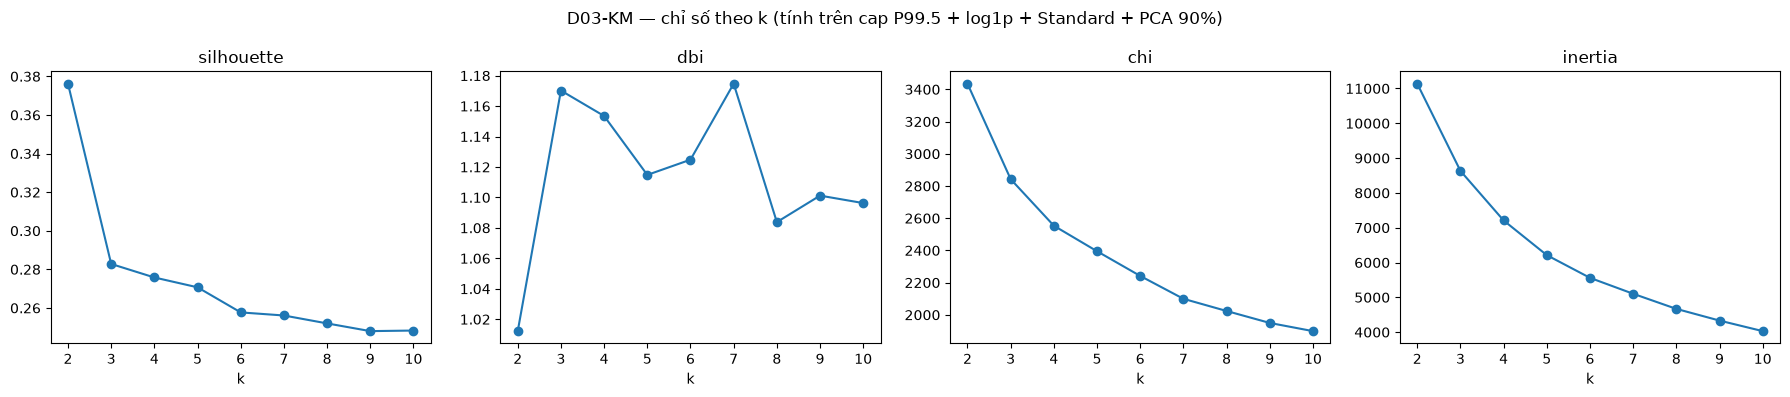

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.3762,1.0122,3435.2,11136.9,1881
1,3,0.2828,1.1702,2842.4,8632.9,1173
2,4,0.2758,1.1535,2553.3,7208.9,956
3,5,0.2707,1.1148,2394.8,6212.7,727
4,6,0.2577,1.1248,2241.5,5560.5,476
5,7,0.2561,1.1747,2099.5,5102.9,440
6,8,0.2520,1.0838,2023.8,4668.8,360
7,9,0.2480,1.1012,1949.6,4332.6,170
8,10,0.2483,1.0963,1898.8,4029.9,141


In [5]:
def sweep(Zs):
    rows, labels_by_k = [], {}
    for k in K_GRID:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Zs)
        labels_by_k[k] = km.labels_
        rows.append({"k": k,
                     "silhouette": round(silhouette_score(Zs, km.labels_), 4),
                     "dbi": round(davies_bouldin_score(Zs, km.labels_), 4),
                     "chi": round(calinski_harabasz_score(Zs, km.labels_), 1),
                     "inertia": round(km.inertia_, 1),
                     "min_cluster": int(np.bincount(km.labels_).min())})
    return pd.DataFrame(rows), labels_by_k

metrics, labels_by_k = sweep(Z)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "chi", "inertia"]):
    ax.plot(metrics["k"], metrics[col], marker="o")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("D03-KM — chỉ số theo k (tính trên cap P99.5 + log1p + Standard + PCA 90%)")
plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics.png", dpi=150)
plt.show()
metrics

**Nhận xét:** Silhouette cao nhất ở **k = 2** (0,3762), rồi giảm xuống 0,2828 ở k = 3 và dao động quanh 0,25–0,28 ở k lớn hơn (thấp nhất 0,2480 ở k = 9). DBI thấp nhất cũng ở k = 2 (1,0122); CHI giảm đều từ 3.435,2 (k = 2) xuống 1.898,8 (k = 10). Trên biểu đồ, Silhouette rơi mạnh từ k = 2 sang k = 3 rồi gần như phẳng; CHI và inertia giảm đều, không có khuỷu rõ. Cụm nhỏ nhất vẫn có ít nhất 141 khách ở mọi k = 2–10, không có cụm vài khách như A02-KM.

## Chọn k và huấn luyện mô hình cuối

In [6]:
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("k được chọn (Silhouette lớn nhất):", best_k)

model = Pipeline([("prep", make_prep(caps_values, None, n_pc)),
                  ("kmeans", KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT))]).fit(X.values)
labels = model["kmeans"].labels_
assert np.allclose(model["prep"].transform(X.values), Z)         # pipeline cho đúng không gian đã quét
assert (labels == labels_by_k[best_k]).all()                     # và đúng nhãn đã quét ở trên
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))

k được chọn (Silhouette lớn nhất): 2
0    1881
1    2446
Name: Số khách, dtype: int64


**Nhận xét:** k = 2 chia 1.881 khách vào cụm 0 (43,5%) và 2.446 khách vào cụm 1 (56,5%) — hai nhóm cỡ gần nhau, cùng kiểu chia như D02-KM (1.942 / 2.385).

## Hồ sơ cụm

Mô tả bằng trung vị **trên thang gốc, trước khi cap** (không phải log hay giá trị đã cắt). `Monetary_share_pct` là tỷ trọng tổng Monetary gốc của cụm.

In [7]:
def profile(lab):
    p = X.assign(cluster=lab).groupby("cluster").agg(
        customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"),
        Monetary_sum=("Monetary", "sum"))
    p["customer_share_pct"] = (100 * p["customers"] / len(X)).round(2)
    p["Monetary_share_pct"] = (100 * p["Monetary_sum"] / p["Monetary_sum"].sum()).round(2)
    return p.drop(columns="Monetary_sum")

prof = profile(labels)
prof.round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,
0,1881,20.0,5.0,1839.3,361.0,84.0,43.5,88.4
1,2446,105.0,1.0,326.4,214.3,19.0,56.5,11.6


**Nhận xét** (tên nhóm chỉ là cách gọi gợi ý từ trung vị):
- Cụm 0 (1.881 khách, 43,5%): Recency 20, Frequency 5, Monetary ≈ 1.839, AOV ≈ 361, Diversity 84 → **nhóm hoạt động: mua gần đây, thường xuyên, chi nhiều**; chiếm **88,4%** tổng Monetary.
- Cụm 1 (2.446 khách, 56,5%): Recency 105, Frequency 1, Monetary ≈ 326, AOV ≈ 214, Diversity 19 → **nhóm mua ít (thường một lần), đã lâu, chi thấp**; 11,6% Monetary.

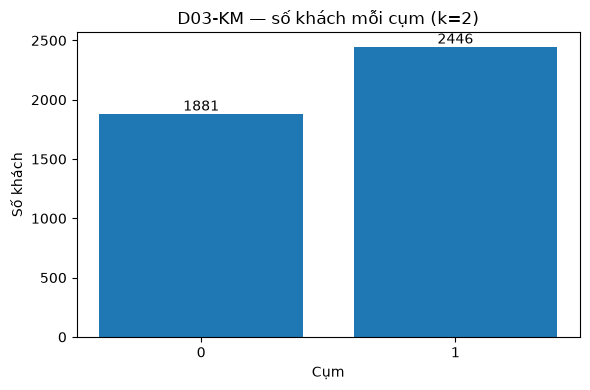

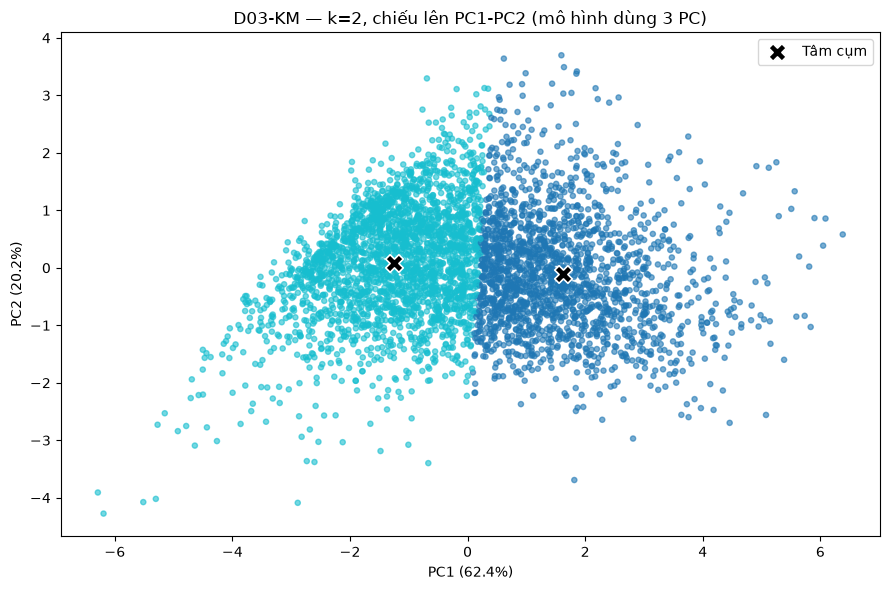

In [8]:
# Hình 1: số khách mỗi cụm
sizes = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(sizes.index.astype(str), sizes.values); ax.bar_label(bars)
ax.set_xlabel("Cụm"); ax.set_ylabel("Số khách"); ax.set_title(f"D03-KM — số khách mỗi cụm (k={best_k})")
plt.tight_layout(); plt.savefig(FIG / "kmeans_cluster_distribution.png", dpi=150); plt.show()

# Hình 2: chiếu lên PC1-PC2 (mô hình dùng n_pc PC)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=14, alpha=0.6)
ctr = model["kmeans"].cluster_centers_
ax.scatter(ctr[:, 0], ctr[:, 1], c="black", marker="X", s=160, edgecolors="white", linewidths=1.2, label="Tâm cụm")
ax.set_xlabel(f"PC1 ({prep['pca'].explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({prep['pca'].explained_variance_ratio_[1]:.1%})")
ax.set_title(f"D03-KM — k={best_k}, chiếu lên PC1-PC2 (mô hình dùng {n_pc} PC)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Hai cụm là hai nửa của cùng một đám mây liên tục, ngăn cách gần như bằng một đường thẳng đứng quanh PC1 ≈ 0 (PC1 chiếm 62,4% phương sai); không có khoảng trống giữa chúng, nên đây là một đường cắt qua dải liên tục (hoạt động nhiều đến ít) chứ không phải hai nhóm tách bạch.

## Kiểm chứng và đối chiếu các mức cap

Tính lại bằng chính code ở trên: (1) tái hiện D04-KM của Thuận (cap P99 + RobustScaler) để kiểm tra pipeline K-Means khớp nhóm; (2) dựng lại D01-KM (P99), D02-KM (P95) và C01-KM (không cap), cùng lưới k và cùng quy tắc chọn; (3) kiểm tra D02-KM dựng lại trùng nhãn đã lưu trong repo. ARI đo mức trùng nhóm giữa hai cách chia, 1,0 là giống hệt. Bảng còn tính Silhouette của mỗi cách chia trên **cả hai không gian**.

In [9]:
# (1) Tái hiện D04-KM của Thuận: cap P99 + RobustScaler(25-75), fit đúng k ông đã chọn
th = json.load(open(find("notebooks/02_baseline_kmeans/19-11-2026-thuan-kmeans-d04/data/kmeans_d04_params.json"), encoding="utf8"))
caps_p99 = make_caps(99)
_, Z_d04, _, _, n_d04 = build_space(caps_p99.to_numpy(), RobustScaler(quantile_range=(25.0, 75.0)))
km_d04 = KMeans(n_clusters=th["k"], random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_d04)
ok_d04 = abs(silhouette_score(Z_d04, km_d04.labels_) - th["silhouette"]) < 1e-4 and abs(km_d04.inertia_ - th["inertia"]) < 0.01
print(f"(1) D04-KM của Thuận: k={th['k']}, Silhouette={th['silhouette']:.4f}, Inertia={th['inertia']:,.2f}")
print(f"    Tính lại ở đây   : k={km_d04.n_clusters}, Silhouette={silhouette_score(Z_d04, km_d04.labels_):.4f}, "
      f"Inertia={km_d04.inertia_:,.2f}, {n_d04} PC | Khớp: {ok_d04}")

# (2) Dãy mức cap: P95 (D02), P99 (D01), P99.5 (D03, ở trên), không cap (C01); cùng Standard + PCA 90%
def fit_space(q):
    c = make_caps(q)
    _, Zq, _, cumq, nq = build_space(c.to_numpy())
    mq, lq = sweep(Zq)
    kq = int(mq.loc[mq["silhouette"].idxmax(), "k"])
    rep, cp, _ = cap_table(X, c)
    return {"q": q, "Z": Zq, "n_pc": nq, "cum": cumq, "metrics": mq, "labels_by_k": lq, "k": kq, "labels": lq[kq],
            "n_capped": int(cp.any(axis=1).sum()), "monetary_cut": float(rep.loc["Monetary", "value_capped_pct"])}

S = {"D02 (P95)": fit_space(95), "D01 (P99)": fit_space(99),
     "D03 (P99.5)": {"q": CAP_Q, "Z": Z, "n_pc": n_pc, "cum": cum, "metrics": metrics, "labels_by_k": labels_by_k,
                     "k": best_k, "labels": labels, "n_capped": n_capped,
                     "monetary_cut": float(cap_report.loc["Monetary", "value_capped_pct"])},
     "C01 (không cap)": fit_space(None)}
assert (fit_space(CAP_Q)["labels"] == labels).all()   # dựng lại D03 bằng hàm chung cho đúng nhãn ở trên

# (3) D02-KM dựng lại phải trùng nhãn đã lưu trong repo (khách theo thứ tự CustomerID của file đặc trưng)
saved_d02 = pd.read_csv(find("notebooks/02_baseline_kmeans/20-11-2026-Nguyen-kmeans-d02/data/kmeans_d02_labels.csv"),
                        dtype={"CustomerID": "string"})
assert (saved_d02["CustomerID"].values == df["CustomerID"].values).all()
ari_saved = adjusted_rand_score(saved_d02["cluster"], S["D02 (P95)"]["labels"])
print(f"(3) ARI giữa D02-KM dựng lại và nhãn đã lưu trong repo: {ari_saved:.4f}")

ladder = pd.DataFrame([{
    "Thí nghiệm": name, "Cap": "không" if s["q"] is None else f"P{s['q']:g}", "Khách bị cap": s["n_capped"],
    "Monetary bị cắt (%)": s["monetary_cut"], "Số PC": s["n_pc"], "k": s["k"],
    "Silhouette": float(s["metrics"].loc[s["metrics"].k == s["k"], "silhouette"].iloc[0]),
    "Kích thước cụm": sorted(np.bincount(s["labels"]).tolist(), reverse=True),
    "ARI vs D03 (k riêng)": round(adjusted_rand_score(S["D03 (P99.5)"]["labels"], s["labels"]), 4),
    "ARI vs D03 (k = 2)": round(adjusted_rand_score(S["D03 (P99.5)"]["labels_by_k"][2], s["labels_by_k"][2]), 4),
    "Silhouette trên không gian D01": round(silhouette_score(S["D01 (P99)"]["Z"], s["labels"]), 4),
    "Silhouette trên không gian D03": round(silhouette_score(Z, s["labels"]), 4)} for name, s in S.items()])
print("Dãy mức cap (cùng Standard + PCA 90%):"); print(ladder.drop(columns=["Kích thước cụm"]).to_string(index=False))
print("\nKích thước cụm:", {r["Thí nghiệm"]: r["Kích thước cụm"] for _, r in ladder.iterrows()})
ladder

(1) D04-KM của Thuận: k=2, Silhouette=0.3648, Inertia=5,753.78
    Tính lại ở đây   : k=2, Silhouette=0.3648, Inertia=5,753.78, 3 PC | Khớp: True
(3) ARI giữa D02-KM dựng lại và nhãn đã lưu trong repo: 1.0000
Dãy mức cap (cùng Standard + PCA 90%):
     Thí nghiệm   Cap  Khách bị cap  Monetary bị cắt (%)  Số PC  k  Silhouette  ARI vs D03 (k riêng)  ARI vs D03 (k = 2)  Silhouette trên không gian D01  Silhouette trên không gian D03
      D02 (P95)   P95           527                34.41      3  2      0.3827                0.9318              0.9318                          0.3754                          0.3742
      D01 (P99)   P99           116                21.62      3  2      0.3770                0.9899              0.9899                          0.3770                          0.3760
    D03 (P99.5) P99.5            53                14.21      3  2      0.3762                1.0000              1.0000                          0.3772                          0.3762
C01 (không c

,Thí nghiệm,Cap,Khách bị cap,Monetary bị cắt (%),Số PC,k,Silhouette,Kích thước cụm,ARI vs D03 (k riêng),ARI vs D03 (k = 2),Silhouette trên không gian D01,Silhouette trên không gian D03
0,D02 (P95),P95,527,34.41,3,2,0.3827,"[2385, 1942]",0.9318,0.9318,0.3754,0.3742
1,D01 (P99),P99,116,21.62,3,2,0.3770,"[2435, 1892]",0.9899,0.9899,0.3770,0.3760
2,D03 (P99.5),P99.5,53,14.21,3,2,0.3762,"[2446, 1881]",1.0000,1.0000,0.3772,0.3762
3,C01 (không cap),không,0,0.00,3,2,0.3754,"[2452, 1875]",0.9945,0.9945,0.3774,0.3763


In [10]:
# ARI theo từng k giữa D03 và các mức cap khác
ari_k = pd.DataFrame({"k": list(K_GRID)})
for name, s in S.items():
    if name.startswith("D03"): continue
    ari_k["ARI D03 vs " + name.split(" ")[0]] = [round(adjusted_rand_score(labels_by_k[k], s["labels_by_k"][k]), 4) for k in K_GRID]
print(ari_k.to_string(index=False))

# Khách nào đổi nhóm giữa D01 (P99) và D03 (P99.5)? (nhóm hoạt động = cụm có Monetary median cao nhất)
def active(lab): return lab == profile(lab)["Monetary"].idxmax()
act03, act01 = active(labels), active(S["D01 (P99)"]["labels"])
n_move = int((act01 ^ act03).sum())
print(f"\nSố khách đổi nhóm giữa D01 và D03 (nhóm hoạt động so với còn lại): {n_move} ({n_move / len(X):.1%})")
print("Bảng chéo (hàng: cụm D01, cột: cụm D03):")
print(pd.crosstab(pd.Series(S["D01 (P99)"]["labels"], name="D01"), pd.Series(labels, name="D03")).to_string())
groups = {"Hoạt động ở cả D01 và D03": act01 & act03, "Mua ít ở cả D01 và D03": ~act01 & ~act03,
          "D01 mua ít -> D03 hoạt động": ~act01 & act03, "D01 hoạt động -> D03 mua ít": act01 & ~act03}
movers = pd.DataFrame([{"Nhóm": n_, "Số khách": int(m.sum()), **X[m].median().round(1).to_dict()} for n_, m in groups.items()])
print(); print(movers.to_string(index=False))

# Đối chiếu phía đuôi: khách bị cap ở P99.5 nằm ở cụm nào, và có đổi nhóm so với D01 không
tail = capped.any(axis=1).to_numpy()
print(f"\nKhách bị cap ở P99.5 ({int(tail.sum())}): theo cụm D03 {np.bincount(labels[tail], minlength=best_k).tolist()}; "
      f"đổi nhóm so với D01: {int((act01 ^ act03)[tail].sum())}")

 k  ARI D03 vs D02  ARI D03 vs D01  ARI D03 vs C01
 2          0.9318          0.9899          0.9945
 3          0.6550          0.9317          0.9700
 4          0.8575          0.9770          0.9882
 5          0.8648          0.9861          0.9693
 6          0.7091          0.9627          0.9778
 7          0.4911          0.5570          0.6306
 8          0.6852          0.9129          0.8896
 9          0.6445          0.9364          0.9674
10          0.7108          0.8346          0.8588

Số khách đổi nhóm giữa D01 và D03 (nhóm hoạt động so với còn lại): 11 (0.3%)
Bảng chéo (hàng: cụm D01, cột: cụm D03):
D03     0     1
D01            
0    1881    11
1       0  2435

                       Nhóm  Số khách  Recency  Frequency  Monetary   AOV  Diversity
  Hoạt động ở cả D01 và D03      1881     20.0        5.0    1839.3 361.0       84.0
     Mua ít ở cả D01 và D03      2435    106.0        1.0     325.8 214.0       19.0
D01 mua ít -> D03 hoạt động         0      NaN     

**Nhận xét:**
- **Pipeline khớp nhóm:** tái hiện D04-KM của Thuận (cap P99 + RobustScaler) cho đúng k = 2, Silhouette 0,3648 và Inertia 5.753,78; D02-KM dựng lại trùng hoàn toàn nhãn đã lưu trong repo (ARI 1,0000).
- **Đổi ngưỡng cap từ P99 sang P99.5 hầu như không đổi cách chia:** cả bốn mức cap (P95, P99, P99.5, không cap) đều chọn k = 2 và cho nhóm hoạt động cỡ 1.875–1.942 khách. ARI giữa D03 và D01 là 0,9899, giữa D03 và C01 là 0,9945 và giữa D03 và D02 là 0,9318. Chỉ **11 khách (0,3%)** đổi nhóm giữa D01 và D03, tất cả chuyển từ nhóm hoạt động ở D01 sang nhóm mua ít ở D03 (Recency trung vị 64, Frequency 3, Monetary ≈ 991, tức khách nằm giữa hai nhóm). **Cả 53 khách bị cap ở P99.5 đều thuộc nhóm hoạt động ở D03 và không ai trong số họ đổi nhóm so với D01.**
- **Silhouette riêng giảm nhẹ khi cap yếu đi, nhưng đó là hiệu ứng của không gian:** 0,3827 (P95), 0,3770 (P99), 0,3762 (P99.5), 0,3754 (không cap). Trên cùng một không gian bốn cách chia chênh nhau dưới 0,003 (không gian D01: 0,3754–0,3774; không gian D03: 0,3742–0,3763) và thứ tự đảo lại: cách chia từ cap yếu hơn nhỉnh hơn một chút. Nên không thể nói cap mạnh hơn tạo cụm tốt hơn.
- **Khác biệt tăng khi k lớn hơn:** ARI giữa D03 và D01 theo k = 2..10 dao động 0,56–0,99, với D02 là 0,49–0,93 và với C01 là 0,63–0,99; k = 7 thấp nhất ở cả ba so sánh, nên cách chia thành 7 cụm nhạy với mức cap hơn các k còn lại.
- **Nhiều khả năng `log1p` đã nén đuôi đủ cho K-Means** nên cap thêm ít tác dụng: độ lệch sau `log1p` ở D03 chỉ khác C01 tối đa 0,13 đơn vị. Thí nghiệm này chưa tách riêng được cơ chế đó, nên đây chỉ là giả thuyết.

## Lưu kết quả

In [11]:
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_d03_labels.csv", index=False)
cap_report.to_csv(OUT / "kmeans_d03_cap_report.csv")
joblib.dump(model, "kmeans_model.pkl")

m = metrics.loc[metrics.k == best_k].iloc[0]
params = {"experiment": "D03-KM", "features": FEATURES, "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "cap_percentile": CAP_Q, "cap_features": CAP_FEATURES,
          "caps": {k: (None if np.isinf(v) else float(v)) for k, v in caps.items()}, "customers_capped": n_capped,
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "k": best_k, "n_customers": int(len(X)),
          "silhouette": float(m["silhouette"]), "dbi": float(m["dbi"]), "chi": float(m["chi"]), "inertia": float(m["inertia"]),
          "ari_vs_d01": float(ladder.loc[ladder["Thí nghiệm"] == "D01 (P99)", "ARI vs D03 (k riêng)"].iloc[0]),
          "ari_vs_d02": float(ladder.loc[ladder["Thí nghiệm"] == "D02 (P95)", "ARI vs D03 (k riêng)"].iloc[0]),
          "ari_vs_c01": float(ladder.loc[ladder["Thí nghiệm"] == "C01 (không cap)", "ARI vs D03 (k riêng)"].iloc[0]),
          "customers_changed_vs_d01": n_move,
          "kmeans_params": model["kmeans"].get_params()}
json.dump(params, open("kmeans_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in Path(".").iterdir() if p.is_file()), sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['Working_details_KMeans_D03.xlsx', 'kmeans_d03.ipynb', 'kmeans_model.pkl', 'kmeans_params.json'] ['kmeans_d03_cap_report.csv', 'kmeans_d03_labels.csv']


## Working_details

Ghi bảng tóm tắt theo đúng bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng theo k, bảng cụm), thêm sheet `So_sanh_cap` (dãy mức cap) và sheet `Cap` (ngưỡng cap, số khách và giá trị bị cắt).

In [12]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "KMeans_D03"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None, sheet=None):
    sh = sheet or ws
    sh[cell] = value
    sh[cell].font = B if bold else Font(name="Calibri")
    if fmt: sh[cell].number_format = fmt

put("A1", "THÍ NGHIỆM K-MEANS — D03 (RFM + AOV + Diversity, cap P99.5, log1p, Standard, PCA 90%)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; chỉ số tính trên Z (không gian đã fit). Khác D01 ở ngưỡng cap (P99.5 thay vì P99)")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary, AOV, Diversity"),
        ("Dữ liệu train", f"Z (cap P99.5 → log1p → Standard → PCA, {n_pc} PC)"),
        ("K được chọn", best_k), ("random_state", RANDOM_STATE), ("init", "k-means++"), ("n_init", N_INIT)]
right = [("max_iter", 300), ("tol", 0.0001), ("Tổng khách hàng", int(len(X))), ("Số cụm", best_k),
         ("PCA", f"90% → {n_pc}/{len(FEATURES)} PC (phương sai {cum[n_pc-1]:.2%})"),
         ("Winsorization", f"P{CAP_Q:g}: {n_capped} khách ({100*n_capped/len(X):.2f}%) bị cap; không xóa khách")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)

for c, v in zip("ABCDEF", ["k", "Silhouette", "DBI", "CHI", "Inertia", "Nhận xét"]): put(f"{c}12", v, bold=True)
for i, r in enumerate(metrics.itertuples(), start=13):
    put(f"A{i}", int(r.k)); put(f"B{i}", r.silhouette, fmt="0.0000"); put(f"C{i}", r.dbi, fmt="0.0000")
    put(f"D{i}", r.chi, fmt="0.00"); put(f"E{i}", r.inertia, fmt="0.00")
    note_ = "k được chọn (Silhouette lớn nhất)" if r.k == best_k else ""
    if r.min_cluster <= 5: note_ = (note_ + "; " if note_ else "") + f"cụm nhỏ nhất chỉ {r.min_cluster} khách"
    put(f"F{i}", note_)

r0 = 13 + len(metrics) + 2
hdr = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)",
       "Monetary (median)", "AOV (median)", "Diversity (median)", "Tỷ trọng Monetary (%)"]
for c, v in zip("ABCDEFGHIJ", hdr): put(f"{c}{r0}", v, bold=True)
med = X.median()
def mo_ta(p):
    return ("Recency xa" if p["Recency"] > med["Recency"] else "Recency gần") + ", " + \
           ("Frequency cao" if p["Frequency"] > med["Frequency"] else "Frequency thấp") + ", " + \
           ("Monetary cao" if p["Monetary"] > med["Monetary"] else "Monetary thấp")
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    put(f"A{j}", int(cl)); put(f"B{j}", mo_ta(p)); put(f"C{j}", int(p["customers"]))
    put(f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(f"E{j}", float(p["Recency"]))
    put(f"F{j}", float(p["Frequency"])); put(f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(f"H{j}", float(p["AOV"]), fmt="0.00"); put(f"I{j}", float(p["Diversity"]))
    put(f"J{j}", float(p["Monetary_share_pct"]), fmt="0.00")
for col, w in zip("ABCDEFGHIJ", [16, 22, 17, 19, 20, 21, 25, 22, 22, 24]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"

ws2 = wb.create_sheet("So_sanh_cap")
cols2 = list(ladder.columns)
for ci, v in enumerate(cols2, start=1): put(ws2.cell(row=1, column=ci).coordinate, v, bold=True, sheet=ws2)
for ri, r in enumerate(ladder.itertuples(index=False), start=2):
    for ci, v in enumerate(r, start=1):
        put(ws2.cell(row=ri, column=ci).coordinate, str(v) if isinstance(v, list) else (float(v) if isinstance(v, (np.floating, float)) else v), sheet=ws2)
nb_ = len(ladder) + 3
put(f"A{nb_}", f"D02-KM dựng lại so với nhãn đã lưu trong repo: ARI = {ari_saved:.4f}", sheet=ws2)
put(f"A{nb_+1}", f"Tái hiện D04-KM (Thuận, cap P99 + Robust): Silhouette {silhouette_score(Z_d04, km_d04.labels_):.4f}, Inertia {km_d04.inertia_:,.2f} (Thuận: {th['silhouette']:.4f}; {th['inertia']:,.2f})", sheet=ws2)
put(f"A{nb_+2}", f"Khách đổi nhóm giữa D01 và D03: {n_move} ({n_move / len(X):.1%})", sheet=ws2)
put(f"A{nb_+3}", "Silhouette/DBI/CHI của các thí nghiệm tính trên các không gian khác nhau nên không so trực tiếp; hai cột Silhouette cuối là phép so cùng không gian.", sheet=ws2)
for ci in range(1, len(cols2) + 1): ws2.column_dimensions[ws2.cell(row=1, column=ci).column_letter].width = 22

ws3 = wb.create_sheet("Cap")
for c, v in zip("ABCDE", ["Biến", f"Ngưỡng cap (P{CAP_Q:g})", "Số khách bị cap", "Tỷ lệ khách bị cap (%)", "Giá trị bị cắt (% tổng)"]):
    put(f"{c}1", v, bold=True, sheet=ws3)
for i, (feat, r) in enumerate(cap_report.iterrows(), start=2):
    put(f"A{i}", feat, sheet=ws3)
    put(f"B{i}", "không cap" if np.isnan(r["cap"]) else float(r["cap"]), fmt="0.00", sheet=ws3)
    put(f"C{i}", int(r["customers_capped"]), sheet=ws3); put(f"D{i}", float(r["customers_capped_pct"]), fmt="0.00", sheet=ws3)
    put(f"E{i}", float(r["value_capped_pct"]), fmt="0.00", sheet=ws3)
put(f"A{len(cap_report) + 3}", f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%); không xóa khách nào ({len(X)} khách còn nguyên).", sheet=ws3)
for col, w in zip("ABCDE", [14, 20, 18, 24, 24]): ws3.column_dimensions[col].width = w

wb.save("Working_details_KMeans_D03.xlsx")
print("Đã lưu Working_details_KMeans_D03.xlsx")

Đã lưu Working_details_KMeans_D03.xlsx


## Kết luận D03-KM

- **K-Means vẫn chọn k = 2** (Silhouette 0,3762; k = 3 chỉ 0,2828): nhóm hoạt động (1.881 khách, 43,5%) giữ 88,4% Monetary và nhóm mua ít (2.446 khách, 56,5%) giữ 11,6%. Cụm nhỏ nhất có ít nhất 141 khách ở mọi k.
- **Số khách và giá trị bị cap ở P99.5:** 53 khách (1,22%), mỗi biến cap 22 khách (0,51%); cắt 14,21% tổng Monetary, 4,16% Frequency, 2,88% AOV và 2,51% Diversity. Bảng cap khớp bảng của Thuận ở D03-GN.
- **Đổi ngưỡng cap từ P99 sang P99.5 hầu như không đổi cách chia:** ARI 0,9899 với D01, chỉ 11 khách (0,3%) đổi nhóm và không ai trong 53 khách bị cap đổi nhóm. Cả dãy P95, P99, P99.5, không cap chỉ cho ARI 0,93–0,99 so với D03 ở k = 2, nên với K-Means k = 2 winsorization không thêm thông tin đáng kể.
- **Pipeline kiểm chứng được:** tái hiện D04-KM của Thuận đúng k, Silhouette và Inertia; D02-KM dựng lại trùng nhãn đã lưu.
- **Giới hạn:** ảnh hưởng của mức cap lớn hơn ở k lớn (ARI D03 so với D01 xuống 0,56 ở k = 7) và ở GMM (Thuận báo ARI giữa D03-GN và D01 là 0,7575); Silhouette không so trực tiếp được giữa các không gian khác nhau; chưa tách riêng vai trò của `log1p`.
- **Bước kế tiếp:** D04-GN (cap P99 cộng RobustScaler) để hoàn tất phần nhóm D của Nguyên.